In [1]:
import pandas as pd
import numpy as np
import random 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy.typing as npt
import pandas as pd
import time
import math
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, explained_variance_score
from math import sqrt
from sklearn.svm import SVR
from sklearn.multioutput import MultiOutputRegressor
from sklearn.pipeline import make_pipeline


In [2]:
df = pd.read_csv('gazebo_full+_dataset_synced.csv')

In [3]:
df

,Time,x,y,z,theta0,theta1,theta2,theta3,theta4,theta5,theta6
0,76.109,0.479692,-0.115205,0.905620,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
1,76.110,0.479692,-0.115205,0.905620,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
2,76.110,0.479692,-0.115205,0.905620,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
3,76.110,0.479692,-0.115205,0.905620,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
4,76.110,0.479692,-0.115205,0.905620,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
...,...,...,...,...,...,...,...,...,...,...,...
95865,1354.681,-0.154206,-0.471443,0.801403,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95866,1354.681,-0.154157,-0.471496,0.801452,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95867,1354.681,-0.154109,-0.471548,0.801501,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95868,1354.681,-0.154060,-0.471601,0.801549,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176


In [4]:
df.describe()

,Time,x,y,z,theta0,theta1,theta2,theta3,theta4,theta5,theta6
count,95870.000000,95870.000000,95870.000000,95870.000000,95870.000000,95870.000000,95870.000000,95870.000000,95870.000000,95870.000000,95870.000000
mean,1510.495158,0.049861,0.022569,0.762274,-0.125948,0.046854,-0.352591,0.800791,-0.258203,-1.375961,-0.190765
std,2219.154855,0.333866,0.352429,0.361617,1.646092,0.954804,2.025295,3.572670,1.530393,7.763283,1.752245
min,76.109000,-0.794150,-0.840471,-0.716202,-2.773854,-2.028950,-8.088039,-2.104892,-2.940508,-43.638002,-16.426336
25%,201.154000,-0.154784,-0.232761,0.478756,-1.540355,-0.570780,-1.313833,-0.620000,-1.628157,-0.828176,-1.351246
50%,315.650000,0.023001,-0.000005,0.789397,0.000013,0.000067,-0.000066,0.049822,-0.000070,-0.000016,-0.000057
75%,1265.010000,0.277337,0.290886,1.075479,1.090419,0.788004,0.909329,1.135364,0.714148,0.831085,0.816528
max,6658.649000,1.000957,0.831571,1.220999,2.867152,1.904753,2.846485,19.466906,2.922250,2.400718,2.957545


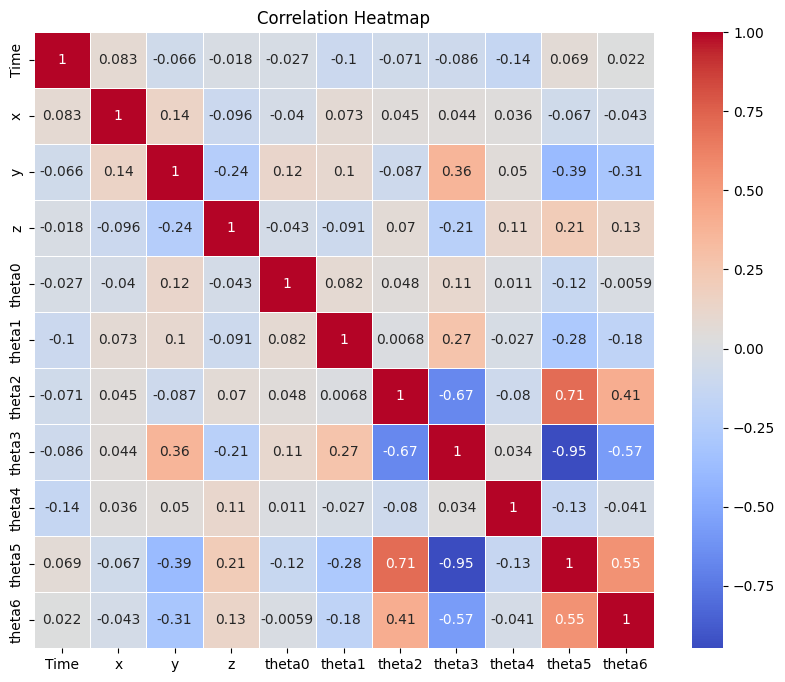

In [5]:
#df = df.iloc[:20000,:]
#Plotting correlation heatmap
correlation_matrix =df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5) 
plt.title("Correlation Heatmap")
plt.show()

In [6]:
y = df.iloc[:,4:]
y

,theta0,theta1,theta2,theta3,theta4,theta5,theta6
0,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
1,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
2,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
3,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
4,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
...,...,...,...,...,...,...,...
95865,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95866,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95867,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95868,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176


In [7]:
X = df.iloc[:,1:4]
X

,x,y,z
0,0.479692,-0.115205,0.905620
1,0.479692,-0.115205,0.905620
2,0.479692,-0.115205,0.905620
3,0.479692,-0.115205,0.905620
4,0.479692,-0.115205,0.905620
...,...,...,...
95865,-0.154206,-0.471443,0.801403
95866,-0.154157,-0.471496,0.801452
95867,-0.154109,-0.471548,0.801501
95868,-0.154060,-0.471601,0.801549


In [8]:
X.shape

(95870, 3)

In [9]:
# Split data into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)

# Scale the data
x_scaler = StandardScaler()
X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.fit_transform(X_test)

# Create the SVR model
svr = SVR(kernel='rbf', C=100, epsilon=0.1)

# Wrap the SVR model in the MultiOutputRegressor
multi_output_svr = MultiOutputRegressor(svr)

# Train the multi-output SVR model
multi_output_svr.fit(X_train_scaled, y_train)


MultiOutputRegressor(estimator=SVR(C=100))

Mean Absolute Error: 0.514
Mean Squared Error: 0.944
Root Mean Squared Error: 0.950
R-squared: 0.925
Explained Variance Score: 0.733


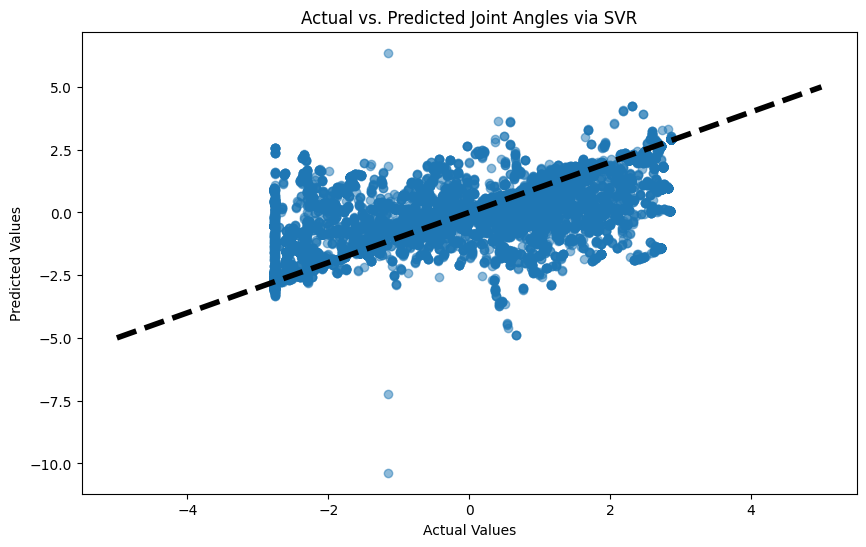

In [10]:
# Evaluate the model performance
predictions = multi_output_svr.predict(X_test_scaled)

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = mean_squared_error(y_test, predictions, squared=False)  # Set squared=False for RMSE
r2 = r2_score(y_test, predictions, multioutput='variance_weighted')  # For multi-output
explained_variance = explained_variance_score(y_test, predictions)

print(f"Mean Absolute Error: {mae:.3f}")
print(f"Mean Squared Error: {mse:.3f}")
print(f"Root Mean Squared Error: {rmse:.3f}")
print(f"R-squared: {r2:.3f}")
print(f"Explained Variance Score: {explained_variance:.3f}")

# Plotting actual vs predicted values for the first dimension as an example
plt.figure(figsize=(10, 6))
plt.scatter(y_test.iloc[:, 0], predictions[:, 0], alpha=0.5)
plt.title('Actual vs. Predicted Joint Angles via SVR')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.plot([-5,5], [-5,5], 'k--', lw=4)
#plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=4)
plt.show()

In [11]:
#y_pred = pd.DataFrame(y_scaler.inverse_transform(y_pred))
#y_test = pd.DataFrame(y_scaler.inverse_transform(y_test))

result_mse = []
result_mae = []

for i in range(7):

    mse = mean_squared_error(y_test.iloc[:,i], predictions[:,i])
    rmse = sqrt(mse) 
    mae = mean_absolute_error(y_test.iloc[:,i], predictions[:,i])
    result_mse.append(mse)
    result_mae.append(mae)

print("RMSE:\n", result_mse)
print("\n\nMAE:\n", result_mae)

RMSE:
 [1.2240172082340859, 0.25071386794544964, 0.9959518075359235, 0.6944893900966304, 1.1694770576691915, 1.237301444678895, 1.032796173986836]


MAE:
 [0.6618304012897567, 0.2665896755749714, 0.5684115489024724, 0.41595237533611457, 0.6169067264552518, 0.4796974230405251, 0.5897728312770726]


In [12]:
#Example prediction
#new_sequence = np.array([[-0.3,-0.3,0.6]])  # New test positions here
#predicted_angles = model.predict(new_sequence)
#print(predicted_angles)


In [14]:
# # Save the trained SVR model
# from sklearn import svm
# from sklearn import datasets
# from joblib import dump
# dump(multi_output_svr, 'multi_output_svr.joblib')

# # Load the trained SVR model
# from joblib import load
# multi_output_svr_loaded = load('multi_output_svr.joblib')

['multi_output_svr.joblib']

-
-
-
-